In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df_aluguel = pd.read_csv("data.csv", low_memory=False)
display(df_aluguel)

,address,district,area,bedrooms,garage,type,rent,total
0,Rua Herval,Belenzinho,21,1,0,Studio e kitnet,2400,2939
1,Avenida São Miguel,Vila Marieta,15,1,1,Studio e kitnet,1030,1345
2,Rua Oscar Freire,Pinheiros,18,1,0,Apartamento,4000,4661
3,Rua Júlio Sayago,Vila Ré,56,2,2,Casa em condomínio,1750,1954
4,Rua Barata Ribeiro,Bela Vista,19,1,0,Studio e kitnet,4000,4654
...,...,...,...,...,...,...,...,...
11652,Avenida Adolfo Pinheiro,Santo Amaro,94,2,1,Apartamento,4100,5778
11653,Rua Professor Alexandre Correia,Jardim Vitória Régia,350,4,4,Apartamento,11250,17480
11654,Rua Abílio Borin,Jardim Caravelas,84,1,2,Apartamento,4500,5467
11655,Rua Forte William,Jardim Fonte do Morumbi,76,1,0,Apartamento,9000,10200


Podemos observar acima a tabela contendo todas as informações do arquivo principal do dataset de Preços de aluguéis em São Paulo: ***"data.csv"***.

No entanto, ela está repartida em **8 colunas(*columns*)**, e **11657 linhas(*rows*)**, cada uma dessas linhas e colunas estão contendo informações sobre o dataset, no código abaixo veremos o que cada linha e coluna representa:

In [29]:
display(list(df_aluguel.columns))


['address', 'district', 'area', 'bedrooms', 'garage', 'type', 'rent', 'total']

Ao inserirmos uma nova célula e digitarmos o código: "**display(list(df_aluguel.columns**))", a mensagem a ser imprimida será uma lista contendo todas as colunas presentes na tabela, sendo eles: **address(*Endereço*), district(*Bairro*),  area(*Área*), bedrooms(*Quartos*), garage(*Vagas na garagem*), type(*Tipo de imóvel*), rent(*Valor do aluguel*), total(*Valor total (aluguel + demais custos*))**.

Em relação as **linhas(*rows*)** estão divididas tendo cada as informações de cada coluna em específico: **'address', 'district', 'area', 'bedrooms', 'garage', 'type', 'rent', 'total'**, assim como mostrado no display. No entanto cada linha terá um valor diferente para cada coluna, como por exemplo:

In [30]:
display(df_aluguel.head(2))

,address,district,area,bedrooms,garage,type,rent,total
0,Rua Herval,Belenzinho,21,1,0,Studio e kitnet,2400,2939
1,Avenida São Miguel,Vila Marieta,15,1,1,Studio e kitnet,1030,1345


Nesse display acima podemos observar que em cada uma das linhas os valores de cada coluna são diferentes, na linha de índice 0, o "address" está como: **"Rua Herval"**, e na de índice 1, está como: **"Vila Marieta"**. Não só essas como também o **valor do aluguel(*rent*)** que na de índice 1 é = **2400,00** , e na de índice 2 é = **1030,00**

Agora verificaremos se há valores ausentes, algum registro repetido ou valores inconcistentes. Ao dar **"display(df_aluguel.info())"** podemos ter as **informações sobre o dataset.**

In [31]:
display(df_aluguel.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11657 entries, 0 to 11656
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   address   11657 non-null  object
 1   district  11657 non-null  object
 2   area      11657 non-null  int64 
 3   bedrooms  11657 non-null  int64 
 4   garage    11657 non-null  int64 
 5   type      11657 non-null  object
 6   rent      11657 non-null  int64 
 7   total     11657 non-null  int64 
dtypes: int64(5), object(3)
memory usage: 728.7+ KB


None

Em relação aos valores ausentes podemos notar que todas as colunas estão totalmente preenchidas ao se  olhar para coluna **"Non-Null Count"** que seriam a quantidade de valores não nulos (***valores preenchidos e não ausentes***) e em todas as colunas constam como **11657 non-null**. No entanto se ouvesse algum valor vazio, poderiamos simplesmente preenchê-los usando o código: **"df_aluguel["coluna_vazia"] = df_aluguel["coluna_vazia"].fillna("Vazio")".**

Mas antes de iniciarmos o tratamento dos dados desta tabelo, criaremos uma outra tabela igual a original, sendo utilizada como teste, para uma analise, para se caso ouver algo de errado com os tratamentos de dados, ou tiver que reverter algo, não estará comprometendo o arquivo principal.

In [41]:
df_analise = df_aluguel
display(df_analise.info())
display(df_analise.describe())
display(list(df_analise.columns))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11657 entries, 0 to 11656
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   address   11657 non-null  object
 1   district  11657 non-null  object
 2   area      11657 non-null  int64 
 3   bedrooms  11657 non-null  int64 
 4   garage    11657 non-null  int64 
 5   type      11657 non-null  object
 6   rent      11657 non-null  int64 
 7   total     11657 non-null  int64 
dtypes: int64(5), object(3)
memory usage: 728.7+ KB


None

,area,bedrooms,garage,rent,total
count,11657.000000,11657.000000,11657.000000,11657.000000,11657.000000
mean,84.655658,1.966286,1.060393,3250.814789,4080.030625
std,74.020536,0.931313,1.132349,2650.711557,3352.480274
min,0.000000,0.000000,0.000000,500.000000,509.000000
25%,40.000000,1.000000,0.000000,1590.000000,1996.000000
50%,60.000000,2.000000,1.000000,2415.000000,3057.000000
75%,96.000000,3.000000,2.000000,3800.000000,4774.000000
max,580.000000,6.000000,6.000000,25000.000000,28700.000000


['address', 'district', 'area', 'bedrooms', 'garage', 'type', 'rent', 'total']

Assim geramos uma tabela secundária utilizada somente para tratar os dados, que é igual a tabela principal. Com isso, iniciaremos o tratamento de dados, començando pelas **duplicatas**.

Em relação as duplicatas, podemos analisar todas as colunas utilizando: **"duplicatas = df_analise[df_analise.duplicated(keep=False)]
print("Quantidade de duplicatas: ", df_analise.duplicated().sum())
display(duplicatas)"** esse código faz com que haja uma verificação se há duplicatas na tabela.

In [49]:
duplicatas = df_analise[df_analise.duplicated(keep=False)]
print("Quantidade de duplicatas: ", df_analise.duplicated().sum())
display(duplicatas)

Quantidade de duplicatas:  0


,address,district,area,bedrooms,garage,type,rent,total


Vemos que não há nenhum valor duplicado constado, mas se fizermos da seguinte forma. Utilizando o comando: 'display(df_analise.duplicated(subset=["address"]))' ele irá fazer uma ***verificação em série boolena*** em que se retorna ***"True"*** caso ela seja uma duplicata de outra anterior, considerando todas as linhas, já se retornar ***"False"*** é o sentido contrário, indicando que aquela linha não é uma duplicata.

In [37]:
display(df_analise.duplicated(subset=["address"]))

,0
0,False
1,False
2,False
3,False
4,False
...,...
11652,True
11653,True
11654,False
11655,True


Aqui vemos que algumas linhas da coluna "address" estão duplicatas, elas retornam o valor **"True"**. Para solucionar isso basta apenas digitar esse comando: **'df_aluguel = df_aluguel.drop_duplicates(subset=["address"])'**.

Após o comando, não irá consta mais nenhuma linha duplicada na coluna **'address'**. Agora poderiamos fazer o mesmo com as outras colunas, mas **será que é necessário?**. Ao anarlisarmos bem, se executassemos esse comando **todas as linhas** em que o mesmo valor da coluna ***'address'*** se repete, **será apagado**, junto também com as demais colunas: **'bedrooms', 'area', etc.** Mas é possível haver um cenário que o endereço de um imóvel seja igual ao endereço de outro imóvel? Sim.

Neste caso, se aplicarmos essa lógica para todas as colunas, a forma mais correta de apagarmos todas as duplicatas da lista seria se as variáveis: ***'address', 'district', 'area', 'bedrooms', 'garage' e 'type'*** forem iguais, mas isso não significaria que fossem **imóveis únicos**, mas que não há ***registros idênticos segundo esses critérios***.

In [55]:
df_analise = df_analise.drop_duplicates(subset=["address", "district", "area", "bedrooms", "garage", "type"])
display(df_analise.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11657 entries, 0 to 11656
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   address   11657 non-null  object
 1   district  11657 non-null  object
 2   area      11657 non-null  int64 
 3   bedrooms  11657 non-null  int64 
 4   garage    11657 non-null  int64 
 5   type      11657 non-null  object
 6   rent      11657 non-null  int64 
 7   total     11657 non-null  int64 
dtypes: int64(5), object(3)
memory usage: 728.7+ KB


None

Após utilizar o comando, vemos que não foi excluida **nenhuma coluna**, pois o código passado foi para excluir linhas em que as **variáveis citadas fossem iguais**, como não, se mantiveram todas as **11657**

Agora verificaremos se há algum valor inconcistente. Faremos 5 etapas de verificações:



1.   Verificar se a coluna "area" em alguma linha é igual ou menor que zero.
2.   Verificar se há valores negativos nas colunas numéricas.
3.   Verificar se o valor total é menor que o aluguel(rent).
4.   Verificar imóveis com zero quartos, bedrooms = 0.
5.   E por último, identificar valores atípicos no aluguel, como: 15000 ou 20000.



In [63]:
df_analise["area"] <= 0

,area
0,False
1,False
2,False
3,False
4,False
...,...
11652,False
11653,False
11654,False
11655,False


Podemos ver que ao digitarmos **"df_aluguel["area"] <= 0"** ele faz uma busca em série booleana em valores cuja a coluna **"area"** seja menor ou igual a 0. Após a busca vemos que **não há nenhum valor inconcistente**. Mas para que não haja realmente nenhum valor igual a 0, vamos atualizar a coluna e colocar somente valores acima 0.

In [65]:
df_analise = df_analise[df_analise['area'] > 0]

Agora foram exluídas todas as colunas de 'area' iguais a 0.

In [66]:
df_analise[["area", "bedrooms", "garage", "rent", "total"]] <= 0

,area,bedrooms,garage,rent,total
0,False,False,True,False,False
1,False,False,False,False,False
2,False,False,True,False,False
3,False,False,False,False,False
4,False,False,True,False,False
...,...,...,...,...,...
11652,False,False,False,False,False
11653,False,False,False,False,False
11654,False,False,False,False,False
11655,False,False,True,False,False


Ao verificarmos todos os valores numéricos, vemos que algumas colunas de **"garage"** retornaram **"True"**, então há locais que não tem garagem em seu estabelecimento, mas isso é comum pois nem todo lugar háverá garagem. Então não há valores inconcistentes.

In [67]:
df_analise["total"] < df_analise["rent"]

,0
0,False
1,False
2,False
3,False
4,False
...,...
11652,False
11653,False
11654,False
11655,False


Verificamos se há algum valor da coluna **"total"** que é menor que a coluna de valor de aluguel(rent) e pelo visto não, então valores concistentes até então.

In [68]:
df_aluguel["bedrooms"] <= 0

,bedrooms
0,False
1,False
2,False
3,False
4,False
...,...
11652,False
11653,False
11654,False
11655,False


Verificação de valores da coluna de **Quartos("bedrooms")** e os valores impressos foram "False", sem valores inconcistentes.

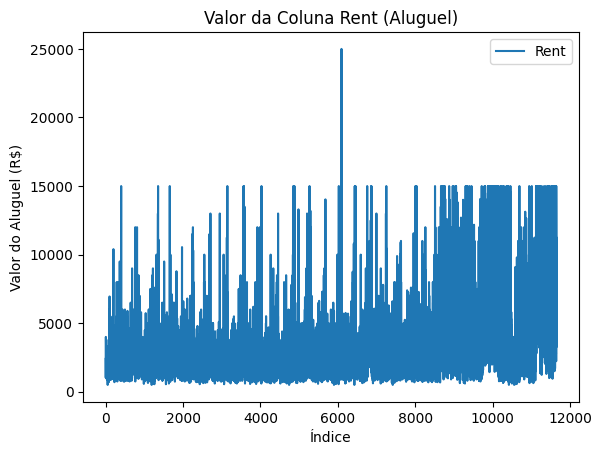

In [69]:
plt.plot(df_analise["rent"])
plt.xlabel('Índice')
plt.ylabel('Valor do Aluguel (R$)')
plt.title('Valor da Coluna Rent (Aluguel)' )
plt.legend(['Rent'])
plt.show()

Utilizando um gráfico, podemos visualizar que há linhas que alcançam a escala de **R$25.000** de acrodo com a representação do gráfico, então ha um valor atípico entre a coluna **"rent"**, e como resolver isso? Simples, aplicamos um comando em que exclua essa coluna, sendo ele:

In [71]:
df_analise = df_analise[df_analise['rent'] <= 15000]

O código acima faz uma atualizição na coluna 'rent' mantendo somente valores abaixo de R$15.000 ou igual.

E com isso fizemos os tratamento de todos os dados, organizando e excluindo valores indesejados, corrigindo colunas vazias e verificando valores atípicos e inconcistentes. Deixando nossa tabela assim no momento:

In [72]:
display(df_analise.info())
display(df_analise.describe())

<class 'pandas.core.frame.DataFrame'>
Index: 11654 entries, 0 to 11656
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   address   11654 non-null  object
 1   district  11654 non-null  object
 2   area      11654 non-null  int64 
 3   bedrooms  11654 non-null  int64 
 4   garage    11654 non-null  int64 
 5   type      11654 non-null  object
 6   rent      11654 non-null  int64 
 7   total     11654 non-null  int64 
dtypes: int64(5), object(3)
memory usage: 819.4+ KB


None

,area,bedrooms,garage,rent,total
count,11654.000000,11654.000000,11654.000000,11654.000000,11654.000000
mean,84.675390,1.966278,1.060408,3249.094560,4078.281019
std,74.019621,0.931340,1.132418,2643.340853,3346.315248
min,1.000000,0.000000,0.000000,500.000000,509.000000
25%,40.000000,1.000000,0.000000,1590.000000,1996.000000
50%,60.000000,2.000000,1.000000,2415.000000,3056.500000
75%,96.000000,3.000000,2.000000,3800.000000,4774.000000
max,580.000000,6.000000,6.000000,15000.000000,28700.000000


Agora iremos calcular a média e a mediana dos aluguéis, utlizaremos o comando **" media = df_aluguel["rent"}.mean()"**  e o **" mediana = df_aluguel["rent"].median()"** :

In [78]:
media = df_aluguel["rent"].mean()
mediana = df_aluguel["rent"].median()
print(f"A média dos aluguéis é: {media}")
print(f"A mediana dos aluguéis é: {mediana}")

A média dos aluguéis é: 3250.9607893607895
A mediana dos aluguéis é: 2415.0


Calculamos a média e a mediana de acordo com as colunas do "rent" e os valores foram: **Média = 3250.96... e Mediana = 2415.0**.  Os valores foram diferentes ,porquê? simples, a média vai **somar todos os valores** da coluna "rent" e **dividir pela quantidade** dando o resultado, já a mediana vai ser o **valor central da coluna** "rent" sendo ele = **2415.0!**

A média também ficou maior por conta de haver valores muito elevados de aluguéis. Há aluguéis acima de **R$10.000.**

Seguindo, vamos identificar as localidades com maiores e menores preços médios, então teriamos que fazer um agrupamento utilizando as colunas: **"address", "rent" e "district"**.

In [74]:
localidades = df_analise.groupby('district')['rent'].agg(
    preco_medio='mean',
    quantidade='count'
)

localidades = localidades[localidades['quantidade'] >= 30]

maiores = localidades.sort_values(
    'preco_medio', ascending=False
).head(20)

menores = localidades.sort_values(
    'preco_medio', ascending=True
).head(20)

print("Maiores preços médios:")
display(maiores.round(2))

print("\nMenores preços médios:")
display(menores.round(2))


Maiores preços médios:


,preco_medio,quantidade
district,,
Jardim Leonor,7455.74,38
Tamboré,6912.68,34
Cerqueira César,6750.66,140
Jardim Paulista,6305.96,220
Paraíso,6285.56,89
Vila Nova Conceição,6246.77,77
Itaim Bibi,6105.29,51
Brooklin Paulista,6074.67,46
Cidade Monções,6034.27,49



Menores preços médios:


,preco_medio,quantidade
district,,
Taboão,1473.14,49
Sé,1593.30,63
Campos Elíseos,1646.79,117
Santa Efigênia,1647.53,43
Vila Ema,1736.86,36
Liberdade,1831.74,141
Centro Histórico de São Paulo,1923.47,73
Penha de França,1975.82,40
Brás,1992.66,141


Nas tabelas acima mostram as localidades com as 20 maiores médias de aluguel, e as 20 menores. Para isso, tivemos que agrupar as colunas **"district"** e **"address"**, e seleciona a coluna ***"rent"*** com as informações dos valores de aluguel, depois criamos a variável: ***"preco_medio = 'mean'"*** que vai fazer o **cálculo das médias dos valores** e a variável: ***"quantidade = 'count'"*** que vai contar a quantidade valores que tem na coluna. Após isso criamos: **"localidades = localidades[localidades['quantidade'] >= 30] "** que remove locais com ***30 ou menos quantidade de imóveis.*** Depois geramos o comando: 'maiores = localidades.sort_values(
    'preco_medio', ascending=False
).head(10)' que simplesmente organiza os bairros pelo preoço médio e são gerados de forma **descrescente(ascending=False)**, gerando a lista das localidades com maiores preços médios, e para fazer a lista de menores, basta colocar a ordem para **crescente(ascending=True)** e pronto, lista dos locais com menores preços médios feita.



Utilizamos o **.head(10)** para imprimir somente 10 linhas, e o **.round(2)** arrendonda os valores para somente duas casas decimais.

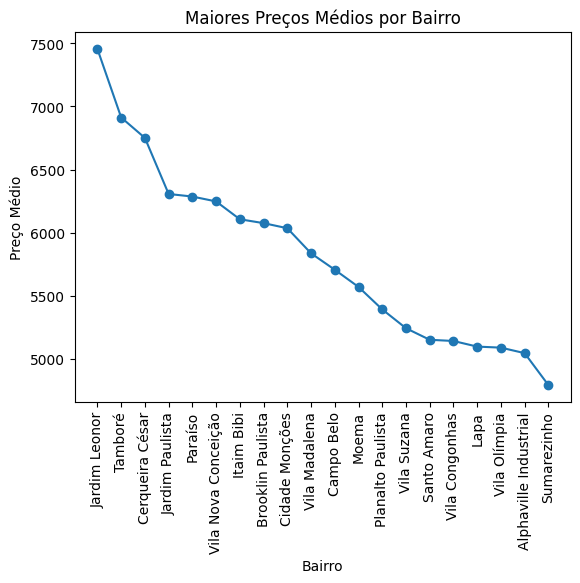

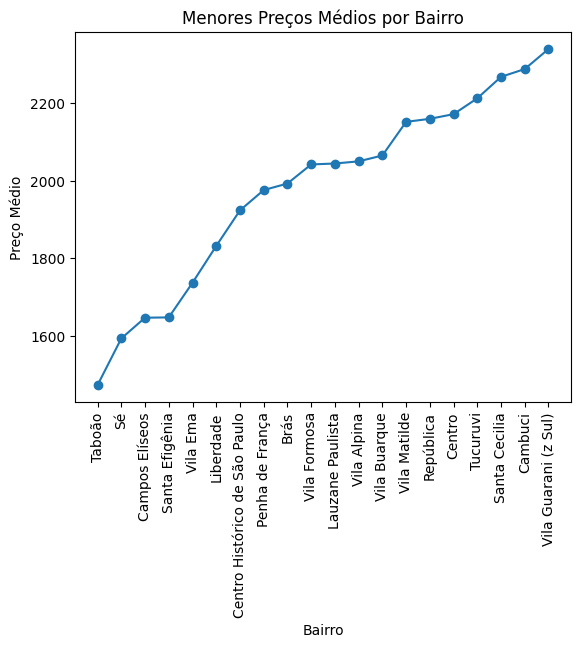

In [75]:
plt.plot(maiores.index, maiores['preco_medio'], marker='o')
plt.xlabel('Bairro')
plt.ylabel('Preço Médio')
plt.title('Maiores Preços Médios por Bairro')
plt.xticks(rotation=90)
plt.show()

plt.plot(menores.index, menores['preco_medio'], marker='o')
plt.xlabel('Bairro')
plt.ylabel('Preço Médio')
plt.title('Menores Preços Médios por Bairro')
plt.xticks(rotation=90)
plt.show()

Vamos utilizar gráficos que permite uma melhor visualização de informações. Acima vemos dois gráficos:

**Gráfico 1** -> Mostra os **20 maiores preços médios**, Cada ponto representa um **bairro**, permitindo comparar os valores e observar as diferenças entre eles.

**Gráfico 2** -> Mostra os 20 menores preços médios, trazendo uma visibilidade melhor para locais com maior acessibilidade.

Em ambos os gráficos, o eixo horizontal **plt.xticks(rotation=90)** representa os bairros e o eixo vertical representa o preço médio do aluguel. A rotação dos nomes em 90° facilita a leitura das localidades.

In [76]:
correlacao_area = df_analise['rent'].corr(df_analise['area'])

correlacao_quartos = df_analise['rent'].corr(df_analise['bedrooms'])

print(f"Correlação entre aluguel e área: {correlacao_area:.2f}")
print(f"Correlação entre aluguel e quartos: {correlacao_quartos:.2f}")

Correlação entre aluguel e área: 0.67
Correlação entre aluguel e quartos: 0.53


No código acima fizemos uma correlação entre colunas, sendo a principal: **"rent"**, e correlacionando ela com as colunas: **"area" e "bedrooms"**.

A correlação entre o **"rent" e a "area"** indica: Se imóveis com **maior área** tendem a ter aluguéis mais altos ou mais baixos.

Já a correlação entre **"rent" e "bedrooms"** indica: Se houver uma maior **quantidade de quartos** no imóvel, tende a ter um aluguel ***mais alto ou mais baixo.***

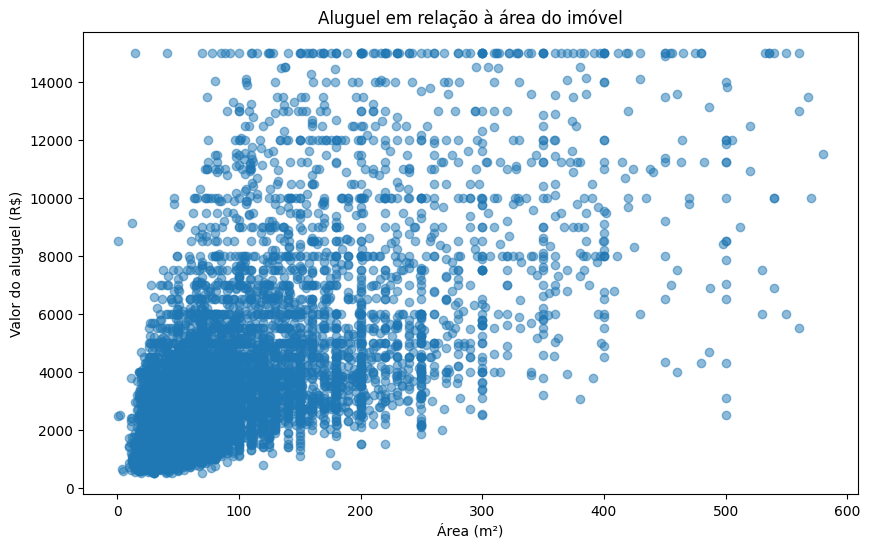

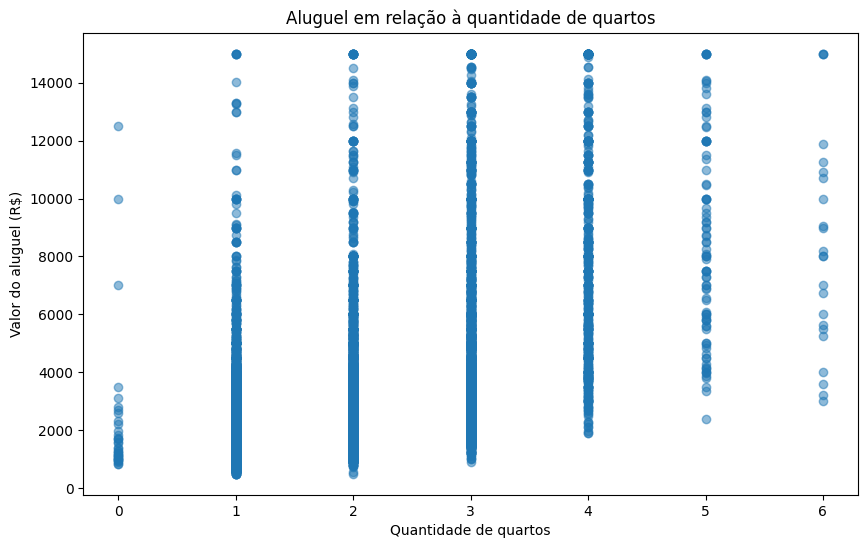

In [79]:
plt.figure(figsize=(10, 6))
plt.scatter(df_analise['area'], df_analise['rent'], alpha=0.5)
plt.xlabel('Área (m²)')
plt.ylabel('Valor do aluguel (R$)')
plt.title('Aluguel em relação à área do imóvel')
plt.show()


plt.figure(figsize=(10, 6))
plt.scatter(df_analise['bedrooms'], df_analise['rent'], alpha=0.5)
plt.xlabel('Quantidade de quartos')
plt.ylabel('Valor do aluguel (R$)')
plt.title('Aluguel em relação à quantidade de quartos')
plt.show()

Criamos um gráfico para facilitar a visualização das correlações:

**Gráfico 1** -> Está representando a relação entre a **área dos imóveis**, em metros quadrados, e o **valor do aluguel**. Cada ponto representa um imóvel. O gráfico permite observar se **imóveis com áreas maiores tendem a apresentar aluguéis mais elevados.**

**Gráfico 2** -> Representa a relação entre o **número de quartos** e o **preço do aluguel**. Cada ponto representa um imóvel, permitindo verificar se **imóveis com mais quartos tendem a ter aluguéis mais caros.**

Com isso podemos tirar 5 conclusões com todo esse progresso feito até então:

1. **A diferença entre a Média e a Mediana:** O preço médio dos aluguéis foi de aproximadamente 3.250,96, enquanto a mediana foi de 2.415,00. Isso indica que os aluguéis mais elevados aumentam a média.

2. **Relação entre os alugueis com a área dos imóveis:** A correlação de aluguel com a área foi de 0.67, indicando uma relação positiva relativamente forte. Em geral, imóveis com áreas maiores tendem a apresentar aluguéis mais elevados.

3. **Relação entre os aluguéis com a quantidade de quartos dos imóveis:** A correlação de quartos com aluguel foi de 0.53, indicando uma relação positiva moderada. Imóveis com mais quartos tendem a apresentar aluguéis maiores, embora essa relação seja menos intensa do que a observada com a área.

4. **Bairros com maiores preços médios:** Entre as localidades analisadas com pelo menos 20 registros, Jardim Leonor apresentou o maior preço médio, de aproximadamente R$ 7.455,74 por mês.

5. **Bairros com menores preços médios:** Entre as localidades que atenderam ao mesmo critério, Taboão apresentou o menor preço médio, de aproximadamente R$ 1.473,14	 por mês. A diferença em relação a Jardim Leonor evidencia variações relevantes entre os bairros analisados.



Algumas limitações das analises com base nas informações fornecidas:

1. **Ausência de informações:** O conjunto de dados não apresenta todos os fatores que podem influenciar o aluguel, como: ***estado de conservação do imóvel, mobiliário, condomínio e proximidade de serviços.***

2. **Concentração dos anúncios:** A quantidade de anúncios varia entre os bairros analisados. Por isso, os resultados de bairros com menos registros podem ser menos representativos.

3. **Preços anunciados:** Os valores representam os preços informados nos anúncios, que podem ser **diferentes dos valores** efetivamente negociados entre proprietários e inquilinos.

4. **Exclusão de registros:** A análise removeu endereços repetidos e anúncios com aluguel superior a R$ 15.000. Essa decisão pode ter excluído imóveis **válidos e influenciado as médias calculadas.**

5. **Dados inconsistentes:** Foram identificados valores de área iguais a zero e registros com zero quartos, que precisam ser verificados para evitar distorções nos resultados.

6. **Correlação não significa causalidade:** Embora a área tenha apresentado correlação positiva com o aluguel, isso não significa que ela seja a única responsável pelo aumento dos preços.

Em suma, os resultados ajudam a compreender os padrões dos aluguéis anunciados em São Paulo, mas devem ser interpretados considerando as limitações e a qualidade dos dados utilizados.

Pergunta orientadora: quais características parecem acompanhar os maiores e os menores preços de aluguel e o que os dados não permitem concluir?


Em resposta a pregunta dados informados pela análise demonstram que a correlação entre a área e os valores de aluguel foram de 0,67 e a correlação entre quartos e aluguéis foram de 0,53 o que indica que um imóvel com uma área bastante extensa e com posse de uma grande quantidade de quartos, faça com que o valor daquele imóvel aumente. Entretanto, há a falta de informações que contam na hora de precificar o imóvel como sua **conservação, condomínio, proximidade de serviços, localidade, infraestrutura**, que não foram informados e com isso não podemos afirma que somente a área e a quantidade de banheiros interferem no aumento ou da diminuição de preço da propriedade.

Então após todos os tratamentos de dados, análises e organizações, a nossa tabela ficaria assim:

In [80]:
display(df_analise.info())
display(df_analise.describe())


<class 'pandas.core.frame.DataFrame'>
Index: 11654 entries, 0 to 11656
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   address   11654 non-null  object
 1   district  11654 non-null  object
 2   area      11654 non-null  int64 
 3   bedrooms  11654 non-null  int64 
 4   garage    11654 non-null  int64 
 5   type      11654 non-null  object
 6   rent      11654 non-null  int64 
 7   total     11654 non-null  int64 
dtypes: int64(5), object(3)
memory usage: 819.4+ KB


None

,area,bedrooms,garage,rent,total
count,11654.000000,11654.000000,11654.000000,11654.000000,11654.000000
mean,84.675390,1.966278,1.060408,3249.094560,4078.281019
std,74.019621,0.931340,1.132418,2643.340853,3346.315248
min,1.000000,0.000000,0.000000,500.000000,509.000000
25%,40.000000,1.000000,0.000000,1590.000000,1996.000000
50%,60.000000,2.000000,1.000000,2415.000000,3056.500000
75%,96.000000,3.000000,2.000000,3800.000000,4774.000000
max,580.000000,6.000000,6.000000,15000.000000,28700.000000
